## KNN for Classification


## Contents:
### I.Dataset
### II.Preprocessing on Dataset
### III.Classification using a custom KNN model
### IV. Classification using a KNN model from scikit-learn library
### V.Student Experiments by changing parameters

---

### I. Dataset



- Dataset source: https://www.kaggle.com/datasets/chik0di/health-and-lifestyle-dataset?select=health_lifestyle_dataset.csv

In [47]:
'''
import sys
!{sys.executable} -m pip install kagglehub
'''

'\nimport sys\n!{sys.executable} -m pip install kagglehub\n'

#### 1.1 Installing dependencies
The first cell (commented out) installs the `kagglehub` library, which
allows us to download the dataset programmatically from Kaggle.

In [48]:
# Download Dataset
import os
import kagglehub

path = kagglehub.dataset_download("chik0di/health-and-lifestyle-dataset")

print("Path to dataset files:", path)
print(os.listdir(path))


Path to dataset files: C:\Users\U-ser\.cache\kagglehub\datasets\chik0di\health-and-lifestyle-dataset\versions\1
['health_lifestyle_dataset.csv']


#### 1.2 Downloading the dataset

Use `kagglehub.dataset_download` to fetch the health and lifestyle dataset. The path where the data is stored is printed, along with the directory contents.

In [49]:
# Loading Dataset
import pandas as pd
data = pd.read_csv(os.path.join(path,"health_lifestyle_dataset.csv"))
print(data.head())

   id  age  gender   bmi  daily_steps  sleep_hours  water_intake_l  \
0   1   56    Male  20.5         4198          3.9             3.4   
1   2   69  Female  33.3        14359          9.0             4.7   
2   3   46    Male  31.6         1817          6.6             4.2   
3   4   32  Female  38.2        15772          3.6             2.0   
4   5   60  Female  33.6         6037          3.8             4.0   

   calories_consumed  smoker  alcohol  resting_hr  systolic_bp  diastolic_bp  \
0               1602       0        0          97          161           111   
1               2346       0        1          68          116            65   
2               1643       0        1          90          123            99   
3               2460       0        0          71          165            95   
4               3756       0        1          98          139            61   

   cholesterol  family_history  disease_risk  
0          240               0             0  
1   

#### 1.3 Loading the CSV into a DataFrame

Read the CSV file using pandas and display the first few rows to understand the structure of the dataset.

In [50]:
# Check for missing values
data.isnull().sum()
# -> there are no missing values

# Convert categorical data to numeric
data["gender"] = data["gender"].map({"Male": 0, "Female": 1})

data

,id,age,gender,bmi,daily_steps,sleep_hours,water_intake_l,calories_consumed,smoker,alcohol,resting_hr,systolic_bp,diastolic_bp,cholesterol,family_history,disease_risk
0,1,56,0,20.5,4198,3.9,3.4,1602,0,0,97,161,111,240,0,0
1,2,69,1,33.3,14359,9.0,4.7,2346,0,1,68,116,65,207,0,0
2,3,46,0,31.6,1817,6.6,4.2,1643,0,1,90,123,99,296,0,0
3,4,32,1,38.2,15772,3.6,2.0,2460,0,0,71,165,95,175,0,0
4,5,60,1,33.6,6037,3.8,4.0,3756,0,1,98,139,61,294,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,53,0,33.1,4726,3.9,2.0,3118,0,1,56,105,76,282,0,0
99996,99997,22,0,35.1,11554,4.5,3.1,1967,0,0,51,149,77,192,0,0
99997,99998,37,0,18.9,3924,3.8,1.0,2328,0,0,69,92,117,218,0,0
99998,99999,72,1,27.8,16110,5.6,0.8,3093,0,0,93,164,72,188,0,0


### II. Data cleaning and preprocessing

Check for missing values (none found) and convert the categorical `gender` column to numeric codes so it can be used by machine learning algorithms.

#### -Inspecting class distribution

Extract the label column and count the number of instances in each class to understand any imbalance.

In [51]:
labels = data.iloc[:,15]
class_0_idx = labels[labels ==0]
class_1_idx = labels[labels == 1]
print("Number of data in class 0: ", len(class_0_idx))
print("Number of data in class 1: ", len(class_1_idx))


class_0_idx.index[100:200]


Number of data in class 0:  75179
Number of data in class 1:  24821


Index([118, 119, 120, 121, 122, 124, 125, 126, 127, 128, 130, 132, 136, 137,
       139, 140, 141, 143, 144, 145, 146, 147, 148, 149, 150, 152, 153, 154,
       155, 162, 164, 166, 167, 168, 170, 171, 172, 173, 174, 175, 176, 177,
       179, 180, 181, 182, 183, 185, 186, 187, 188, 189, 190, 191, 193, 194,
       195, 196, 197, 198, 199, 200, 201, 202, 203, 205, 206, 208, 209, 210,
       211, 212, 213, 214, 215, 216, 217, 218, 219, 221, 222, 223, 224, 225,
       226, 228, 229, 230, 231, 232, 233, 235, 236, 239, 240, 241, 243, 244,
       245, 247],
      dtype='int64')

#### - Balancing the dataset

To avoid bias, select an equal number of samples from each class.
Here we take the first 2000 indices from each class.

In [52]:
# Select only 2000 samples from each class (class 0 and class 1)
# therefore:
class_0_idx_500 = class_0_idx.index[:2000]
class_1_idx_500 = class_1_idx.index[:2000]
len(class_1_idx_500)

2000

#### - Combining and verifying selections

Append the selected indices from both classes and check that the total number
of labels matches expectations.

In [53]:
# combine all indexs of class 0 and class 1 in order
total_selected_labels = class_0_idx_500.append(class_1_idx_500)
len(total_selected_labels)

4000

#### - Separating features and labels

**Create `x_data` containing the feature columns
**and `y_data` for the target variable. 

Print them to verify the selection.

In [54]:
x_data = data.iloc[total_selected_labels, 1:15] # Features/input
y_data = data.iloc[total_selected_labels,15] # target/label/output

print("x_data: ", x_data)
print("y_data: ", y_data)

x_data:        age  gender   bmi  daily_steps  sleep_hours  water_intake_l  \
0      56       0  20.5         4198          3.9             3.4   
1      69       1  33.3        14359          9.0             4.7   
2      46       0  31.6         1817          6.6             4.2   
3      32       1  38.2        15772          3.6             2.0   
4      60       1  33.6         6037          3.8             4.0   
...   ...     ...   ...          ...          ...             ...   
8113   26       0  31.1         4524          6.8             1.6   
8115   21       0  39.2         8340          5.6             4.1   
8118   36       1  28.0         8958          7.0             2.1   
8124   30       0  24.5         3047          3.4             3.6   
8126   74       1  33.8         7406          3.7             2.8   

      calories_consumed  smoker  alcohol  resting_hr  systolic_bp  \
0                  1602       0        0          97          161   
1                  2346 

In [55]:
y_one = y_data[y_data==1]
y_zeros = y_data[y_data==0]
print(len(y_zeros))
print(len(y_one))


2000
2000


#### - Outlier removal
Calculate the interquartile range (IQR) for each feature and filter out rows that fall outside the typical range.

In [56]:
# remove outliers

import numpy as np
Q1 = np.percentile(x_data, 25, axis=0)
Q3 = np.percentile(x_data, 75, axis=0)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
mask = ((x_data >= lower) & (x_data <= upper)).all(axis=1)
x_data_clean = x_data[mask]
y_data_clean = y_data[mask]

x_data_clean, y_data_clean

(      age  gender   bmi  daily_steps  sleep_hours  water_intake_l  \
 0      56       0  20.5         4198          3.9             3.4   
 1      69       1  33.3        14359          9.0             4.7   
 2      46       0  31.6         1817          6.6             4.2   
 3      32       1  38.2        15772          3.6             2.0   
 4      60       1  33.6         6037          3.8             4.0   
 ...   ...     ...   ...          ...          ...             ...   
 8113   26       0  31.1         4524          6.8             1.6   
 8115   21       0  39.2         8340          5.6             4.1   
 8118   36       1  28.0         8958          7.0             2.1   
 8124   30       0  24.5         3047          3.4             3.6   
 8126   74       1  33.8         7406          3.7             2.8   
 
       calories_consumed  smoker  alcohol  resting_hr  systolic_bp  \
 0                  1602       0        0          97          161   
 1                

#### - Feature importance
Use *mutual information* to estimate how useful each feature is for predicting the target class. Higher scores suggest more informative features.

In [57]:
from sklearn.feature_selection import mutual_info_classif
mi_scores = mutual_info_classif(x_data_clean, y_data_clean)

#### - Train/test split

Divide the cleaned dataset into training and testing subsets.  The test size
is 20 % of the data, and a fixed `random_state` ensures reproducibility.

In [58]:
# Split data into train and test sets
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(
    x_data_clean, y_data_clean, 
    test_size=0.2,  # 20% for testing
    random_state=42  # ensures reproducibility
    )

#### - Feature scaling

Normalize the features using `StandardScaler` so that each feature has zero
mean and unit variance. This helps KNN with distance calculations.

In [59]:
# Scale features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

####  - Convert to NumPy and inspect shapes

Transform the training and testing sets into NumPy arrays and print their shapes to ensure everything is in the expected format.

In [60]:
import numpy as np
x_train = np.array(x_train)
y_train = np.array(y_train)

x_test = np.array(x_test)
y_test = np.array(y_test)

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(2559, 14)
(2559,)
(640, 14)
(640,)


### III. Classification using a custom KNN model
#### 3.1 Train custom KNN model

Instantiate the custom `MyKNNModel` class, specifying hyperparameters such as number of neighbors, distance metric, and weighting. Fit it to the training set.

In [61]:
# Classification using a custom-implemented KNN model

import numpy as np
from my_knn_model import MyKNNModel

my_model = MyKNNModel(k=5, distance_type="euclidean", weight_type="inverse_square", p=2)  # using default parameters such as k=3, distance_type="euclidean", weight_type="uniform"

my_model.fit(x_train,y_train)

#### 3.2 Make predictions
Use the trained custom model to predict labels for the test set.

In [62]:
# Test the model predictions
y_pred = my_model.predict(x_test)

print(y_pred)

[0 1 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 0 0 1 0 0 1 1 1 1 1 1 1 0 0 1 1 1
 0 1 1 0 1 0 1 1 1 1 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 1 1 1 1 0 1 0 1 0 0 0 0
 0 0 1 0 0 1 1 0 1 0 0 1 1 1 0 1 1 1 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0 1 0 1 1
 0 0 1 1 0 0 0 0 1 0 0 1 0 1 0 0 0 1 1 0 0 0 1 1 1 0 1 1 1 0 1 1 0 0 0 1 1
 0 1 0 1 1 1 1 0 1 0 1 0 0 1 0 1 1 1 1 1 0 1 0 1 0 1 0 1 0 0 1 1 1 0 0 0 0
 0 0 1 1 0 1 0 0 0 0 0 0 1 0 0 1 1 1 0 1 0 0 1 1 0 0 0 0 0 1 0 0 1 0 1 1 0
 1 1 0 1 1 1 1 1 1 1 0 0 0 0 1 1 1 1 1 1 0 1 0 1 0 1 1 0 0 0 0 1 0 1 0 1 0
 1 1 1 0 1 1 0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1
 1 0 1 0 1 1 1 1 0 1 1 1 1 0 0 0 0 0 1 0 1 0 1 1 0 0 1 1 0 0 0 1 1 1 1 1 0
 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 0 1 0 0 1 0 1 0 0 0 1 0 0 1 0 0 1 1 1 0 1 1
 1 0 1 0 0 0 1 0 0 0 0 0 1 0 1 1 1 1 0 1 1 0 1 1 0 0 1 0 0 1 1 0 1 1 0 1 0
 0 1 0 0 0 0 1 1 0 1 0 0 0 1 1 0 1 0 1 1 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 0 1
 0 1 1 1 1 1 1 0 1 0 1 1 1 0 1 1 1 1 0 0 0 0 1 1 1 1 1 1 0 1 1 1 0 1 1 1 1
 0 1 0 1 1 1 1 1 1 1 1 1 

#### 3.3 Evaluate custom model
Compute the accuracy of the custom model's predictions on the test set.

In [63]:
# Evaluate model performance 
# 1. Calculate accuracy
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.5078125


### IV. Using scikit-learn's KNN

Train a standard `KNeighborsClassifier` from scikit-learn with `k=3` and
evaluate its accuracy. This provides a baseline for comparison.

In [64]:
# KNN model from scikit-learn
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)  # choose k=3

knn.fit(x_train, y_train) # Train model

y_pred_knn = knn.predict(x_test) # Test model

scikit_accuracy = accuracy_score(y_test, y_pred_knn) # Evaluate model performance
print("Accuracy:", scikit_accuracy)

Accuracy: 0.5


#### - ROC curve

Plot the Receiver Operating Characteristic (ROC) curve and compute the area
under the curve (AUC) to assess the model's discriminative ability.

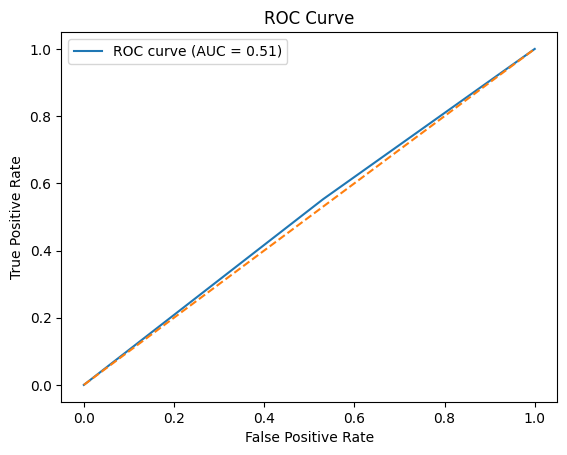

In [65]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label="ROC curve (AUC = %0.2f)" % roc_auc)
plt.plot([0,1], [0,1], linestyle="--")  # random classifier line

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

### V. Student Experiments by changing parameters

- The goal is to observe how different parameter settings affect the classification performance.
- The following parameters will be modified during the experiments:
  - Number of neighbors (k)
  - Distance calculation formula
  - Weighting method
- Changing these parameters helps evaluate how the KNN model behaves under different conditions and determine which configuration produces better results.
---

#### - Experiment 1: Changing the Value of k

->Change the number of neighbors using the following values:k=[3,5,7,9]

+ During this experiment:

    - Keep the distance metric fixed (e.g., Euclidean distance).
    - Keep the weighting method fixed (e.g., uniform weights).

+ Goal:
  - Observe how the choice of k affects the model accuracy.


+ Questions to consider:
  - Does a smaller k make the model more sensitive to noise?
  - Does a larger k produce smoother predictions?
---

In [66]:
k = [3,5,7,9]

accuracies = []

for idx_k in range(len(k)):

    my_model = MyKNNModel(k=k[idx_k], distance_type="euclidean", weight_type="inverse_square", p=2) 
    # First iteration: k =3
    my_model.fit(x_train, y_train)
    y_preds = my_model.predict(x_test)
    scikit_accuracy = accuracy_score(y_test, y_preds)

    accuracies.append(scikit_accuracy) # [accuracy when k = 3,accuracy when k = 5,accuracy when k = 7,accuracy when k = 9]


# plot graph to compare accuracy when changing number of k
# x-axist is represent k values
# y-axist is represernt accuracy for each k


In [67]:
print(accuracies)

[0.5046875, 0.5078125, 0.49375, 0.475]


#### - Experiment 2: Changing the Distance Metric
Test different distance formulas used to measure similarity between data points.

Examples:Euclidean distance, Manhattan distance, Chebyshev distance

+ During this experiment:

- Fix the value of k (e.g.,k=5).

+ Keep the weighting method fixed.

+ Goal:
  Evaluate how different distance metrics affect classification performance.

---

In [68]:
distance_types = ["euclidean", "manhattan", "chebyshev", "minkowski"]
accuracies = []
for idx_dis in range(len(distance_types)):

    my_model = MyKNNModel(k=5, distance_type= distance_types[idx_dis], weight_type="inverse_square", p=2) 
    # First iteration: k =3
    my_model.fit(x_train, y_train)
    y_preds = my_model.predict(x_test)
    scikit_accuracy = accuracy_score(y_test, y_preds)

    accuracies.append(scikit_accuracy)
    
    #........

In [69]:
print(accuracies)

[0.5078125, 0.50625, 0.509375, 0.5078125]


#### - Experiment 3: Changing the Weighting Method
Test different weighting approaches for the neighbors.

Examples: Uniform weights (all neighbors have equal influence), Distance weights (closer neighbors have more influence)

+ During this experiment:
  - Fix the value of k.
  - Fix the distance metric.

+ Goal:
  Understand how weighting strategies influence the final prediction.

In [71]:
weight_types = ["uniform", "inverse", "inverse_square", "linear", "exp"]
accuracies = []
for idx_weight in range(len(weight_types)):

    my_model = MyKNNModel(k=5, distance_type= "chebyshev", weight_type=weight_types[idx_weight], p=2) 
    # First iteration: k =3
    my_model.fit(x_train, y_train)
    y_preds = my_model.predict(x_test)
    scikit_accuracy = accuracy_score(y_test, y_preds)

    accuracies.append(scikit_accuracy)
    
    #........

In [72]:
print(accuracies)

[0.5078125, 0.509375, 0.509375, 0.5125, 0.509375]
